In [2]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
from tensorflow.keras.optimizers import Adam
import keras
from keras.models import Sequential, Model
from keras.layers import *
from keras.utils import Sequence
from keras.layers import Conv2D, MaxPooling2D, Conv2DTranspose
from qkeras import *

from keras.utils import Sequence
from keras.callbacks import CSVLogger
from keras.callbacks import EarlyStopping
from keras.losses import MeanSquaredError, CategoricalCrossentropy

import os
import random
from datetime import datetime
import time
import math


import matplotlib.pyplot as plt

pi = 3.14159265359

maxval=1e9
minval=1e-9

2026-08-18 03:21:53.567940: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [3]:
import importlib
import DAE_DataGenerator
import dataset_utils
import SoftQuantizeLayer
import AnnealingScheduler

importlib.reload(DAE_DataGenerator)
importlib.reload(dataset_utils)
importlib.reload(SoftQuantizeLayer)
importlib.reload(AnnealingScheduler)

from AnnealingScheduler import AnnealingScheduler
from DAE_DataGenerator import OptimizedDataGenerator
from dataset_utils import add_noise, quantize_manual
#from dataprep import *
# from OptimizedDataGenerator_v2 import OptimizedDataGenerator
from loss import *


In [1]:
dataset_base_dir = "/uscms/home/bweiss/nobackup/smart-pixels/"
tfrecords_base_dir = os.path.join(dataset_base_dir, "tfrecords")

# dataset_dir_train = os.path.join(dataset_base_dir, "/dataset_3sr_16x16_50x12P5_parquets", 'train/')
# dataset_dir_val = os.path.join(dataset_base_dir, "dataset_3sr_16x16_50x12P5_parquets", 'test/')

dataset_dir_train = os.path.join(dataset_base_dir, "dataset_3sr_16x16_50x12P5_centeredIncidence_parquets", 'train_contained/')
dataset_dir_val = os.path.join(dataset_base_dir, "dataset_3sr_16x16_50x12P5_centeredIncidence_parquets", 'test_contained/')

# tfrecords_dir_train = os.path.join(tfrecords_base_dir, "TFR_train",'SQDAE_80eN_catgoricalOut_Target_0_7_23_134_404_867_1748')
# tfrecords_dir_val   = os.path.join(tfrecords_base_dir, "TFR_val",'SQDAE_80eN_catgoricalOut_Target_0_7_23_134_404_867_1748')

tfrecords_dir_train   = os.path.join(tfrecords_base_dir, "TFR_train",'SQDAE_3srCI_40eN_catgoricalOut_Target_0_30_845')
tfrecords_dir_val   = os.path.join(tfrecords_base_dir, "TFR_val",'SQDAE_3srCI_40eN_catgoricalOut_Target_0_30_845')



# tfrecords_dir_train = os.path.join(tfrecords_base_dir, "TFR_train",'3sr_16x16_80eN_raw')
# tfrecords_dir_val   = os.path.join(tfrecords_base_dir, "TFR_val",'3sr_16x16_80eN_raw')


print(dataset_dir_val)
batch_size = 5000
val_batch_size = 5000
train_file_size = 80
val_file_size = 20

/uscms/home/bweiss/nobackup/smart-pixels/dataset_3sr_16x16_50x12P5_centeredIncidence_parquets/test_contained/


In [4]:
start_time = time.time()
validation_generator = OptimizedDataGenerator(
    dataset_base_dir = dataset_dir_val,
    file_type = "parquet",
    data_format = "3D",
    batch_size = val_batch_size,
    # optimize_batch_size = True,
    file_count = val_file_size,
    to_standardize= False,
    log_scale = False,
    select_contained = True,
    noise = [0,40],
    # charge_thresholds= [247.80, 668.41, 1662.85],
    charge_thresholds= [0, 30, 845],
    # charge_thresholds= [0, 7, 23, 134, 404, 867, 1748],
    bitwise_categorical = True,
    # charge_thresholds = None,
    labels_list = ['x-midplane','y-midplane','cotBeta'],
    input_shape = (2,16,16), # (20,13,21),
    transpose = (0,2,3,1),
    shuffle = False, 
    files_from_end=True,

    tfrecords_dir = tfrecords_dir_val,
    use_time_stamps = [0,19],
    max_workers = 2
)
# validation_generator = [validation_generator[:][0], validation_generator[:][0]]

print("--- Validation generator %s seconds ---" % (time.time() - start_time))

Processing Files...: 100%|██████████| 20/20 [00:05<00:00,  3.53it/s]


Directory /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/SQDAE_3srCI_40eN_catgoricalOut_Target_0_30_845 is removed...


Saving batches as TFRecords:   0%|          | 0/21 [00:00<?, ?it/s]2026-08-18 03:22:25.935150: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2026-08-18 03:22:25.973724: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2026-08-18 03:22:25.974241: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2026-08-18 03:22:25.975385: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 FMA
To en

Metadata saved successfully ast /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/SQDAE_3srCI_40eN_catgoricalOut_Target_0_30_845/metadata.json
Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/SQDAE_3srCI_40eN_catgoricalOut_Target_0_30_845/metadata.json


--- Validation generator 17.246506929397583 seconds ---


In [ ]:
print(validation_generator[0][0][28][:,:,1])
print(np.argmax(validation_generator[0][1][28], axis = -1)[:,:,1])

In [6]:
print(validation_generator.dataset_logmax, validation_generator.dataset_logmin)

16.239303966535875 -11.77206435145071


In [5]:
# training generator
start_time = time.time()
training_generator = OptimizedDataGenerator(
    dataset_base_dir = dataset_dir_train,
    file_type = "parquet",
    data_format = "3D",
    batch_size = batch_size,
    # optimize_batch_size = True,
    file_count = train_file_size,
    to_standardize= False,
    select_contained = True,
    log_scale = False,
    labels_list = ['x-midplane','y-midplane','cotBeta'],
    input_shape = (2,16,16), # (20,13,21),
    transpose = (0,2,3,1),
    shuffle = False, # True 
    noise = [0, 40],
    # charge_thresholds= [247.80, 668.41, 1662.85],
    charge_thresholds= [0, 30, 845],
    # charge_thresholds = [0, 7, 23, 134, 404, 867, 1748],
    bitwise_categorical = True,
    # charge_thresholds = None,

    # threshold = 400,
    tfrecords_dir = tfrecords_dir_train,
    use_time_stamps = [0,19],
    max_workers = 2
)

# training_generator = [training_generator[:][0], training_generator[:][0]]

print("--- Training generator %s seconds ---" % (time.time() - start_time))

Processing Files...: 100%|██████████| 80/80 [00:20<00:00,  3.92it/s]


Directory /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_train/SQDAE_3srCI_40eN_catgoricalOut_Target_0_30_845 does not exist and cannot be removed.


Saving batches as TFRecords: 100%|██████████| 84/84 [00:41<00:00,  2.03it/s]


Metadata saved successfully ast /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_train/SQDAE_3srCI_40eN_catgoricalOut_Target_0_30_845/metadata.json
Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_train/SQDAE_3srCI_40eN_catgoricalOut_Target_0_30_845/metadata.json


--- Training generator 63.12902069091797 seconds ---


In [5]:
#### Loading pre-generated TFRecords
validation_generator = OptimizedDataGenerator(
    load_from_tfrecords_dir= tfrecords_dir_val,
    shuffle=False,
    # seed=42,
    quantize=False,
    bitwise_categorical = True,
)

training_generator = OptimizedDataGenerator(
    load_from_tfrecords_dir = tfrecords_dir_train,
    shuffle=False,
    # seed=42,
    quantize=False,
    bitwise_categorical = True,
)

Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/SQDAE_3srCI_0eN_catgoricalOut_Target_0_30_856/metadata.json


Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_train/SQDAE_3srCI_0eN_catgoricalOut_Target_0_30_856/metadata.json


<class 'tensorflow.python.framework.ops.EagerTensor'>


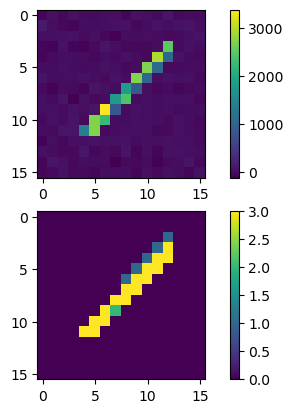

In [6]:
fig, ax = plt.subplots(2,1)
batch_index = 0
N = 18
ts = 1

X_in = validation_generator[batch_index][0][N]
X_out = validation_generator[batch_index][1][N]


a = ax[0].imshow(X_in[:,:,ts]) 
fig.colorbar(a)
a = ax[1].imshow(np.argmax(X_out[:,:,ts,], axis = -1)) 
print(type(X_in))


fig.colorbar(a)


In [12]:
import loss
importlib.reload(loss)
from loss import CustomSSIMClass, CustomSSIM
import models
importlib.reload(models)
from models import *


model=CreateSQAutoencoder_Conv2D((16,16,2), n_filters=5, pool_size=3,
                        decoder_filters = 128, initial_thresholds=[10,80,800], 
                                     OutBits = 2, conv_kernel_size = 3)

#UNCOMMENT to Initialize from Weights
weights_path = './SQ_DAE/model-20014e96-SQDAE_Conv2D_Categorical_2bit_0eN_Target_0_30_856_V2-checkpoints/'
base_dir = weights_path
checkpoint_files = [os.path.join(base_dir, f) for f in os.listdir(base_dir) if f.endswith('.hdf5')]
best_weights = max(checkpoint_files, key=os.path.getmtime)
print(f"Loading model from {best_weights}")
model.load_weights(best_weights)


model.compile(
    # optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    optimizer=tf.keras.optimizers.Nadam(learning_rate=2e-3, clipnorm=1.0),
    # loss=MeanSquaredError()
    # loss=CustomSSIMClass(xrange = xrange, log_standardize = False),
    # loss=CustomSSIM(logxrange = xrange, 
    #                 log_standardize = True)
    loss = CategoricalCrossentropy(reduction = 'sum', from_logits=True
                                  )
    # run_eagerly=True
)

model.summary()

Loading model from ./SQ_DAE/model-20014e96-SQDAE_Conv2D_Categorical_2bit_0eN_Target_0_30_856_V2-checkpoints/weights.1754-t124361.5547-v118714.4141.hdf5
Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 16, 16, 2)]       0         
                                                                 
 soft_quantizer_output (Soft  (None, 16, 16, 2)        4         
 QuantizeLayer)                                                  
                                                                 
 q_separable_conv2d (QSepara  (None, 14, 14, 5)        33        
 bleConv2D)                                                      
                                                                 
 q_activation (QActivation)  (None, 14, 14, 5)         0         
                                                                 
 q_conv2d (QConv2D)          (None, 14, 1

In [13]:
from datetime import datetime
tname = 'SQDAE_Conv2D_Categorical_2bit_240eN_Target_0_30_856'#0_7_23_134_404_867_1748'
fingerprint = '%08x' % random.randrange(16**8)
timestamp = datetime.now().strftime('%Y%m%d-%H%M%S')
os.makedirs("trained_models", exist_ok=True)
base_dir = f'./SQ_DAE/model-{fingerprint}-{tname}-checkpoints'
os.makedirs(base_dir, exist_ok=True)  
checkpoint_filepath = base_dir + '/weights.{epoch:02d}-t{loss:.4f}-v{val_loss:.4f}.hdf5'
print("fingerprint: ", fingerprint)

fingerprint:  f255d673


In [14]:
from tensorflow.keras.callbacks import CSVLogger, EarlyStopping, ModelCheckpoint, Callback
import csv

early_stopping_patience = 500

class CustomModelCheckpoint(ModelCheckpoint):
    def on_epoch_end(self, epoch, logs=None):
        super().on_epoch_end(epoch, logs)
        checkpoints = [f for f in os.listdir(base_dir) if f.startswith('weights')]
        if len(checkpoints) > 1:
            checkpoints.sort(key=lambda x: os.path.getmtime(os.path.join(base_dir,x)))
            for checkpoint in checkpoints[:-1]:
                os.remove(os.path.join(base_dir, checkpoint))

class SoftQuantizeLoggerCallback(Callback):
    def __init__(self, log_filepath, layer_name="soft_quantizer_output"):
        super().__init__()
        self.log_filepath = log_filepath
        self.layer_name = layer_name
        self.header_written = False

    def on_train_begin(self, logs=None):
        os.makedirs(os.path.dirname(self.log_filepath), exist_ok=True)

    def on_epoch_end(self, epoch, logs=None):
        try:
            layer = self.model.get_layer(self.layer_name)
            if not hasattr(layer, 'n_bits'):
                 print(f"\nWarning: Layer '{self.layer_name}' is not a SoftQuantizeLayer. Skipping logging.")
                 return
        except ValueError:
            print(f"\nWarning: Layer '{self.layer_name}' not found in the model. Skipping logging.")
            return

        if not self.header_written:
            num_levels = layer.num_levels
            num_thresholds = num_levels - 1
            
            header = ['epoch', 'k']
            header.extend([f'level_{i}' for i in range(num_levels)])
            header.extend([f'threshold_{i}' for i in range(num_thresholds)])

            header.append('raw_first_level')
            header.extend([f'raw_log_level_delta_{i}' for i in range(num_levels - 1)])
            header.append('raw_first_threshold')
            if hasattr(layer, 'log_threshold_deltas'):
                header.extend([f'raw_log_threshold_delta_{i}' for i in range(num_thresholds - 1)])

            with open(self.log_filepath, mode='w', newline='') as f:
                writer = csv.writer(f)
                writer.writerow(header)
            self.header_written = True

        k_val = layer.k.numpy().item()
        levels = layer.levels.numpy().tolist()
        thresholds = layer.thresholds.numpy().tolist()
        
        # first_level = layer.first_level.numpy().item()
        # log_level_deltas = layer.log_level_deltas.numpy().tolist()
        # first_threshold = layer.first_threshold.numpy().item()
        
        row_data = [epoch, k_val]
        row_data.extend(levels)
        row_data.extend(thresholds)
        # row_data.append(first_level)
        # row_data.extend(log_level_deltas)
        # row_data.append(first_threshold)
        
        if hasattr(layer, 'log_threshold_deltas'):
            log_threshold_deltas = layer.log_threshold_deltas.numpy().tolist()
            row_data.extend(log_threshold_deltas)
        
        with open(self.log_filepath, mode='a', newline='') as f:
            writer = csv.writer(f)
            writer.writerow(row_data)


csv_logger = CSVLogger(f'{base_dir}/training_log.csv', append=True)
scheduler_callback = AnnealingScheduler(
    schedule='cosine',  
    target_layer_name='soft_quantizer_output', 
    initial_k=1.0,
    final_k=200.0, 
    verbose=1      
)

quantizer_logger = SoftQuantizeLoggerCallback(
    log_filepath=f"{base_dir}/soft_quantizer_state_log.csv", # New, more descriptive filename
    layer_name="soft_quantizer_output"
)

es = EarlyStopping(patience=early_stopping_patience, restore_best_weights=True)

mcp = CustomModelCheckpoint(
    filepath=checkpoint_filepath,
    save_weights_only=True,
    monitor='val_loss',
    save_best_only=True,
    save_freq='epoch',
    verbose=1
)


In [15]:
history = model.fit(
        x=training_generator,
        validation_data=validation_generator,
        callbacks=[es, mcp, csv_logger,scheduler_callback, quantizer_logger],
        epochs=4000,
        shuffle=False,
        verbose=1
    )


Epoch 1: Annealing 'k' set to 1.0000
	Levels: 0.0000, 1.0000, 2.0000, 3.0000
	Thresholds: 29.8494, 854.8454, 856.6132
	Tau: [427.4227    413.38187     1.7677765]
Epoch 1/4000


2026-07-06 16:28:43.081392: I tensorflow/stream_executor/cuda/cuda_blas.cc:1614] TensorFloat-32 will be used for the matrix multiplication. This will only be logged once.
2026-07-06 16:28:43.141576: I tensorflow/stream_executor/cuda/cuda_dnn.cc:384] Loaded cuDNN version 8800


84/84 [==============================] - ETA: 0s - loss: 851899.1875
Epoch 1: val_loss improved from inf to 594714.68750, saving model to ./SQ_DAE/model-f255d673-SQDAE_Conv2D_Categorical_2bit_240eN_Target_0_30_856-checkpoints/weights.01-t851899.1875-v594714.6875.hdf5
84/84 [==============================] - 61s 585ms/step - loss: 851899.1875 - val_loss: 594714.6875

Epoch 2: Annealing 'k' set to 1.0000
	Levels: 0.0000, 1.0000, 2.0000, 3.0000
	Thresholds: 29.1980, 853.4028, 855.0775
	Tau: [426.7014    412.93973     1.6747191]
Epoch 2/4000
84/84 [==============================] - ETA: 0s - loss: 553888.2500
Epoch 2: val_loss improved from 594714.68750 to 526073.25000, saving model to ./SQ_DAE/model-f255d673-SQDAE_Conv2D_Categorical_2bit_240eN_Target_0_30_856-checkpoints/weights.02-t553888.2500-v526073.2500.hdf5
84/84 [==============================] - 22s 257ms/step - loss: 553888.2500 - val_loss: 526073.2500

Epoch 3: Annealing 'k' set to 1.0001
	Levels: 0.0000, 1.0000, 2.0000, 3.0000
	

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)




Epoch 184: val_loss did not improve from 225286.48438
84/84 [==============================] - 26s 310ms/step - loss: 234181.4688 - val_loss: 233326.2500

Epoch 185: Annealing 'k' set to 2.0372
	Levels: 0.0000, 1.0000, 2.0000, 3.0000
	Thresholds: 553.8302, 938.8642, 1200.5068
	Tau: [469.4321  323.33835 261.6427 ]
Epoch 185/4000
84/84 [==============================] - ETA: 0s - loss: 234691.1094
Epoch 185: val_loss did not improve from 225286.48438
84/84 [==============================] - 23s 277ms/step - loss: 234691.1094 - val_loss: 226871.5312

Epoch 186: Annealing 'k' set to 2.0485
	Levels: 0.0000, 1.0000, 2.0000, 3.0000
	Thresholds: 562.2011, 947.7905, 1207.7800
	Tau: [473.89526 322.7895  259.98953]
Epoch 186/4000
84/84 [==============================] - ETA: 0s - loss: 230751.0156
Epoch 186: val_loss did not improve from 225286.48438
84/84 [==============================] - 23s 272ms/step - loss: 230751.0156 - val_loss: 230708.6719

Epoch 187: Annealing 'k' set to 2.0598
	Levels

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)

